In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from dizx.circuit_extractor import to_stim
from dizx.realisation import resource_states
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import surgery_hybrid_linear

In [2]:
d = 3
s, real, S = surgery_hybrid_linear(d, "ZZ", rounds=(2, 2, 2))
states = sorted(resource_states(real, S), key=lambda c: (min(real.positions[v][2] for v in c),
                                                         min(real.positions[v][0] for v in c)))
fusions = [link for link in real.links if link.kind == "fusion" and set(link.interaction.ends) <= S]
print("merge layers", len({real.positions[v][2] for v in s.seam_nodes(real)}))
print("resource states", [len(c) for c in states])
print("fusions inside the region", len(fusions), "| fusions across its boundary",
      sum(link.kind == "fusion" for link in real.links) - len(fusions))

merge layers 5
resource states [9, 2, 3, 9, 9, 9, 3, 2]
fusions inside the region 15 | fusions across its boundary 16


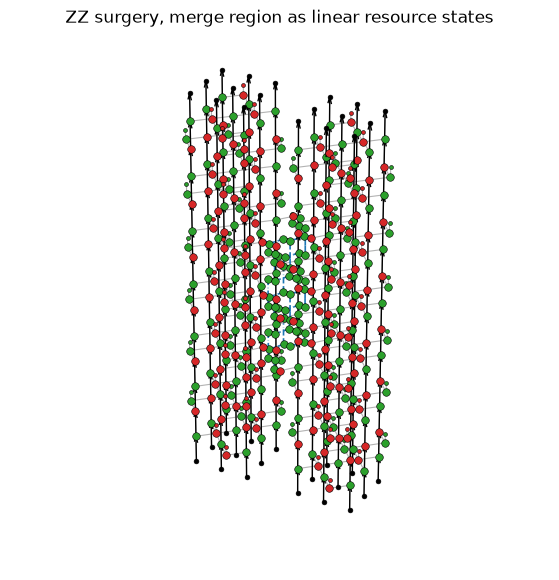

In [3]:
(real.draw(title="ZZ surgery, merge region as linear resource states"))
plt.show()

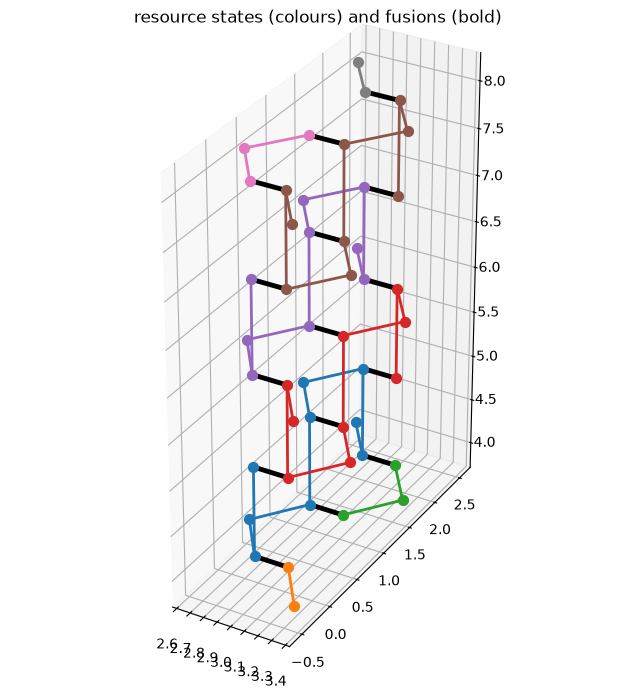

In [4]:
def draw_states(real, states, ax=None, title=None):
    """Each resource state in its own colour; fusions inside the region bold black."""
    ax = ax or plt.figure(figsize=(8, 8)).add_subplot(projection="3d")
    pos = real.positions
    cmap = plt.get_cmap("tab10")
    linked = {frozenset(link.interaction.ends): link for link in real.links}
    for k, c in enumerate(states):
        col = cmap(k % 10)
        for it in [it for it in interactions(real, real.worldlines) if set(it.ends) <= c
                   and frozenset(it.ends) not in linked]:
            p = np.array([pos[v] for v in it.nodes], float)
            ax.plot(*p.T, color=col, lw=2)
        p = np.array([pos[v] for v in c], float)
        ax.scatter(*p.T, color=col, s=50, depthshade=False)
    for e, link in linked.items():
        if link.kind == "fusion" and e <= set().union(*states):
            p = np.array([pos[v] for v in link.interaction.nodes], float)
            ax.plot(*p.T, "k-", lw=3.5)
    ax.set_title(title or "")
    ax.set_box_aspect(np.ptp(np.array([pos[v] for c in states for v in c], float), axis=0) + 0.5)
    return ax

from dizx.realisation import interactions
draw_states(real, states, title="resource states (colours) and fusions (bold)")
plt.show()

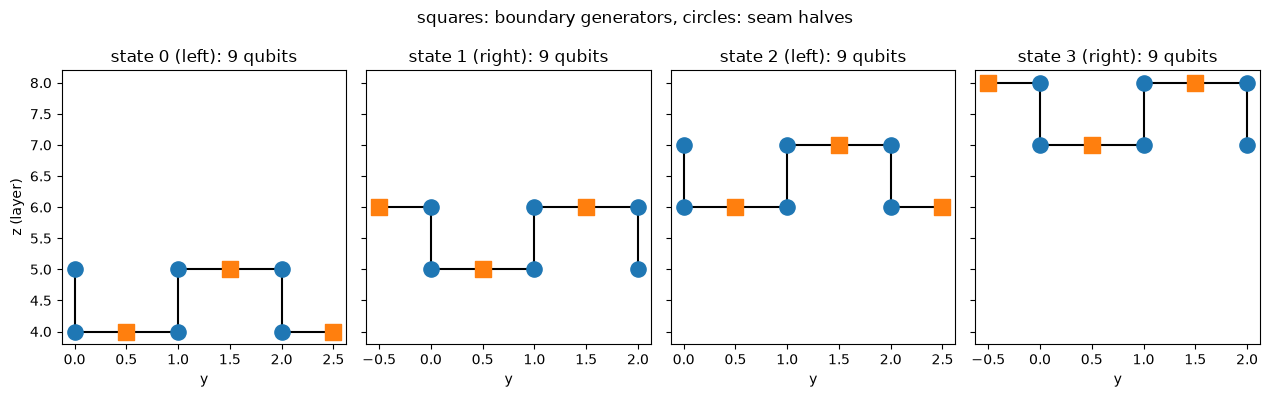

In [5]:
# Each resource state lies on one side of the seam: flatten to (y, z).
linked = {frozenset(link.interaction.ends) for link in real.links}
big = [st for st in states if len(st) > 3]
fig, axes = plt.subplots(1, len(big), figsize=(3.2 * len(big), 4), sharey=True)
for k, (ax, c) in enumerate(zip(axes, big)):
    for it in interactions(real, real.worldlines):
        if set(it.ends) <= c and frozenset(it.ends) not in linked:
            (u, v) = it.ends
            ax.plot([real.positions[u][1], real.positions[v][1]],
                    [real.positions[u][2], real.positions[v][2]], "k-", lw=1.5)
    for v in c:
        _, y, z = real.positions[v]
        ax.scatter(y, z, s=120, marker="s" if v[0] == "gen" else "o",
                   color="tab:orange" if v[0] == "gen" else "tab:blue", zorder=3)
    side = "left" if np.mean([real.positions[v][0] for v in c]) < s.seam[0][0] else "right"
    ax.set_title(f"state {k} ({side}): {len(c)} qubits")
    ax.set_xlabel("y")
axes[0].set_ylabel("z (layer)")
fig.suptitle("squares: boundary generators, circles: seam halves")
plt.tight_layout()
plt.show()

In [6]:
# The chain order of one 9-qubit resource state: a generator, a seam half,
# the next layer's seam half, the next generator, ...
import networkx as nx
c = next(st for st in states if len(st) == 9)
g = nx.Graph()
g.add_edges_from(it.ends for it in interactions(real, real.worldlines)
                 if set(it.ends) <= c and frozenset(it.ends) not in
                 {frozenset(link.interaction.ends) for link in real.links})
ends = [v for v in g if g.degree(v) == 1]
nx.shortest_path(g, *ends)

[('data', 2, 'X', (3, 0)),
 ('data', 2, 'Z', (3, 0)),
 ('gen', 2, 10),
 ('data', 2, 'Z', (3, 1)),
 ('data', 2, 'X', (3, 1)),
 ('gen', 2, 11),
 ('data', 2, 'X', (3, 2)),
 ('data', 2, 'Z', (3, 2)),
 ('gen', 2, 12)]

In [7]:
# Detectors through fusions inside the region.
fused = {v for link in fusions for v in link.interaction.ends}
through = [w for w in real.detectors if any(set(e[:2]) & fused for e in w.support())]
len(through), len(real.detectors)

(14, 96)

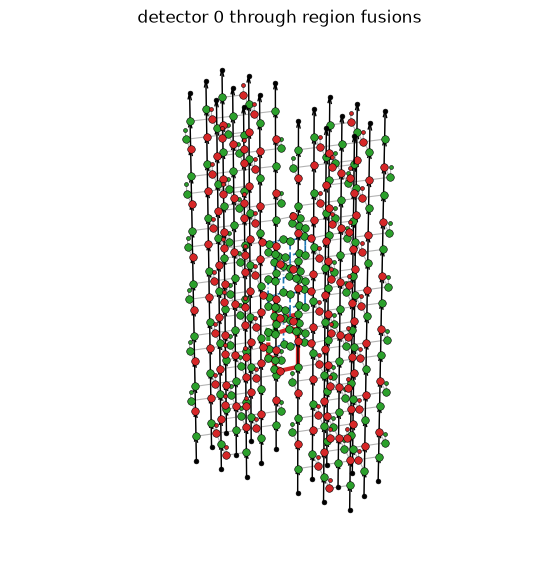

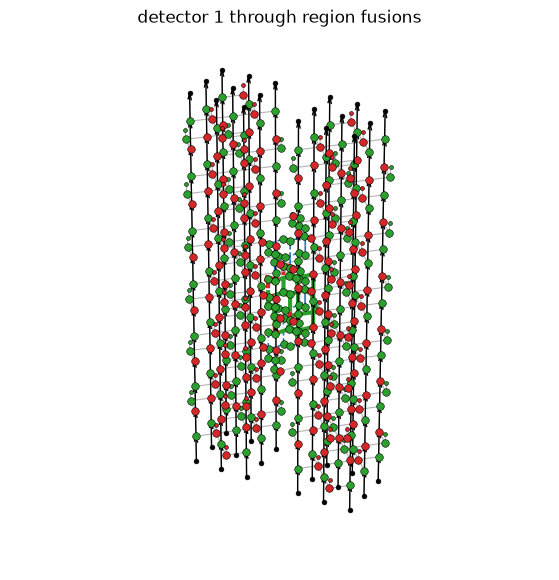

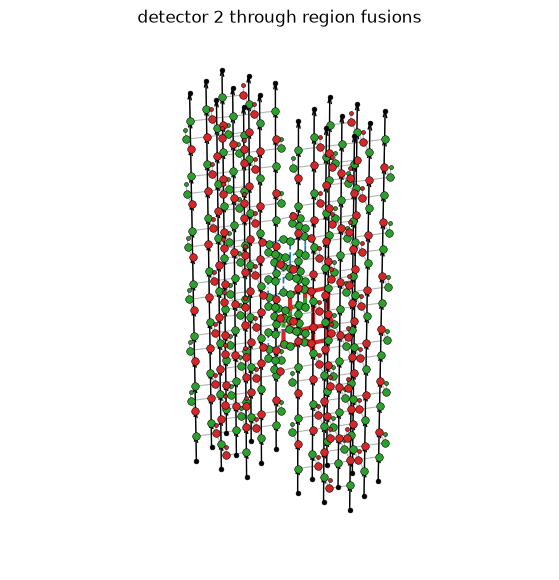

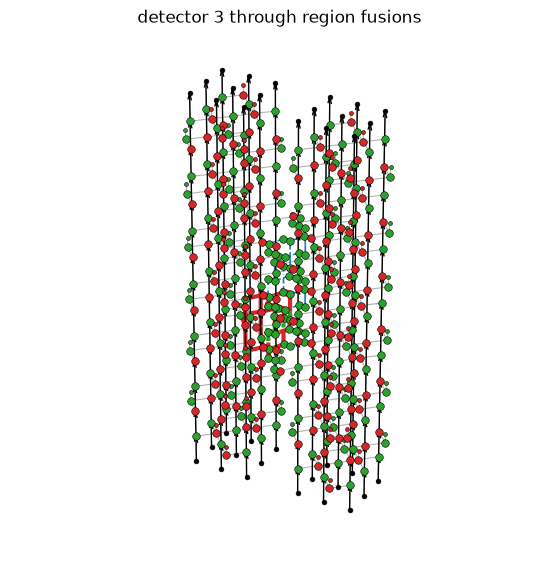

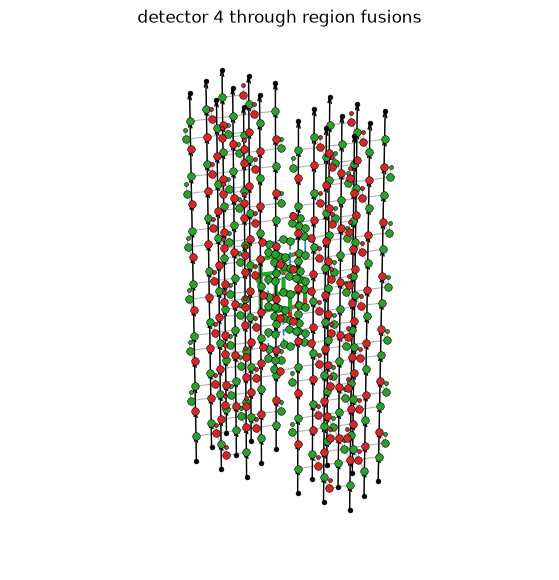

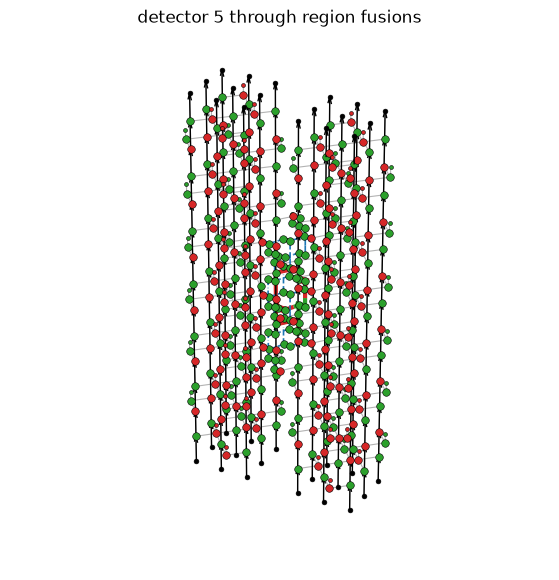

In [8]:
for k, w in enumerate(through[:6]):
    (real.draw(w, title=f"detector {k} through region fusions"))
    plt.show()

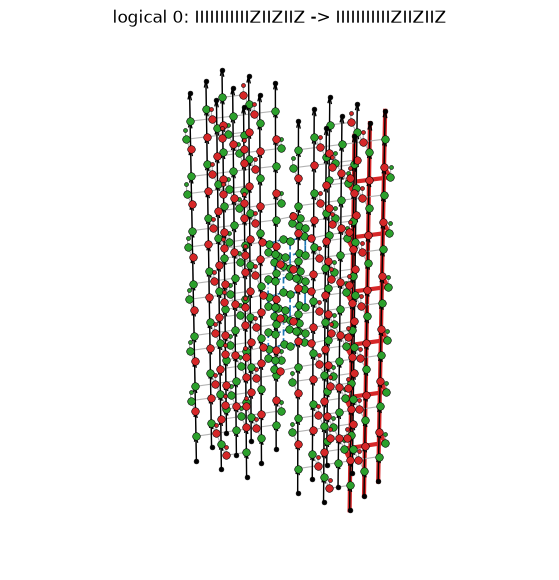

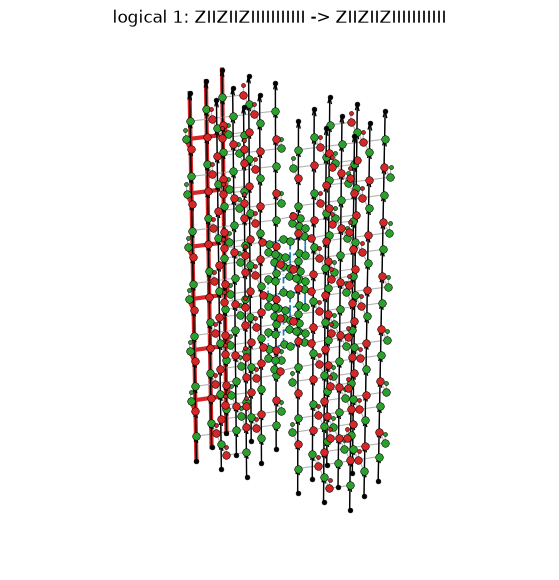

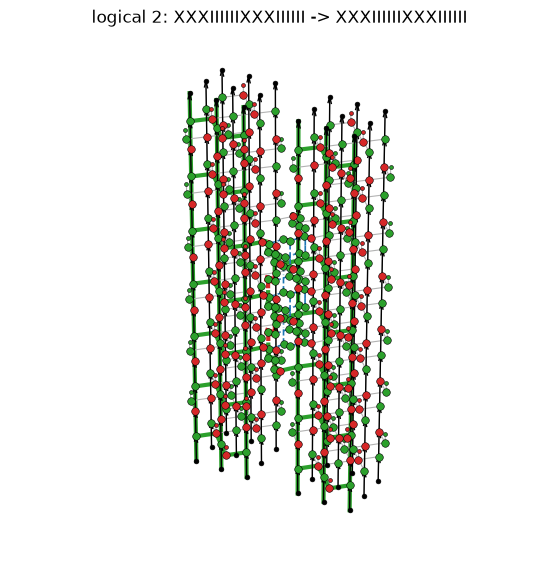

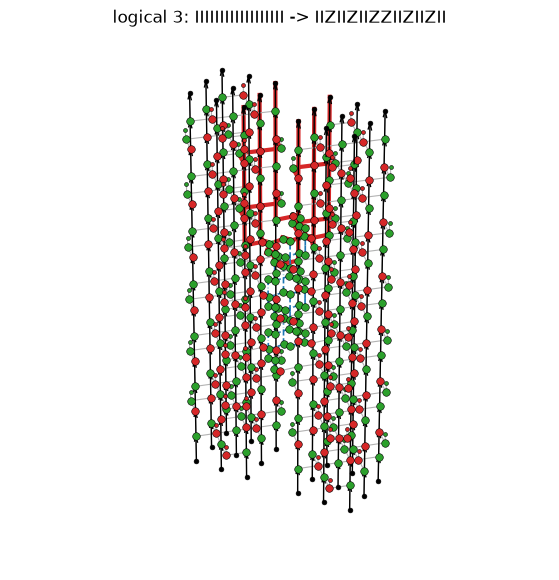

In [9]:
for k, w in enumerate(real.logicals):
    (real.draw(w, title=f"logical {k}: {w.boundary()[0]} -> {w.boundary()[1]}"))
    plt.show()

In [10]:
def distance(c, p=1e-3):
    """Noise on CX, measurements and fusions."""
    import stim
    noisy = stim.Circuit()
    for inst in c.flattened():
        if inst.name in ("M", "MX", "MPP"):
            noisy.append(inst.name, inst.targets_copy(), p)
            continue
        noisy.append(inst)
        if inst.name == "CX":
            noisy.append("DEPOLARIZE2", inst.targets_copy(), p)
    return len(noisy.search_for_undetectable_logical_errors(
        dont_explore_detection_event_sets_with_size_above=4, dont_explore_edges_with_degree_above=4,
        dont_explore_edges_increasing_symptom_degree=False))

for looped in (False, True):
    sl, rl, _ = (s, real, S) if not looped else surgery_hybrid_linear(d, "ZZ", rounds=(2, 2, 2), looped=True)
    for patch_basis in "ZX":
        c = to_stim(sl.experiment(patch_basis, realised=rl), RotatedSurfaceCodeSchedule(sl.merged))
        print("looped" if looped else "plain ", patch_basis, "qubits", c.num_qubits, "distance", distance(c))

plain  Z qubits 58 distance 3


plain  X qubits 58 distance 2


looped Z qubits 67 distance 3


looped X qubits 67 distance 3
